---
title: "Self-study Lab 9 (optional): Logistic Regression with More Than Two Classes"
subtitle: "Machine Learning, Lecture 4: Logistic regression"
author: "Khiem Nguyen"
format:
  html:
    toc: true
    toc-depth: 3
    embed-resources: true
    code-overflow: wrap
    fig-align: center
jupyter: python3
---

## Objectives

The lecture covers **binary** classification. This optional lab extends logistic regression to $K \ge 2$ classes (**multinomial** or **softmax** regression). You will

- define the softmax model and see that it reduces to the sigmoid model for $K = 2$;
- implement the softmax function, the cross-entropy cost and its gradient, vectorised;
- train the model with gradient descent and compare it with scikit-learn;
- draw the decision regions of a three-class classifier.

## Tools

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

np.set_printoptions(precision=3, suppress=True)   # print arrays with 3 decimals, no e-notation

## A three-class problem

We generate $30$ examples for each of $K = 3$ classes, around three different centres. As in scikit-learn, we label the classes $0, 1, \dots, K-1$; only the number of classes matters, not the values of the labels.

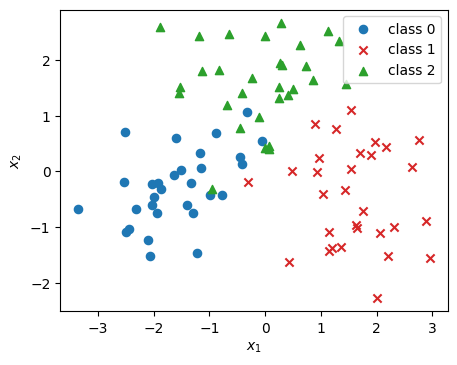

In [2]:
rng = np.random.default_rng(0)
centres = np.array([[-1.5, -0.5], [1.5, -0.5], [0.0, 1.6]])
X_train = np.vstack([rng.normal(c, 0.8, size=(30, 2)) for c in centres])   # shape (90, 2)
y_train = np.repeat([0, 1, 2], 30)                                         # shape (90,)
K = 3
markers, colours = ['o', 'x', '^'], ['tab:blue', 'tab:red', 'tab:green']

def plot_data(X, y, ax=None):
    ax = plt.gca() if ax is None else ax
    for k in range(K):
        ax.scatter(X[y == k, 0], X[y == k, 1], marker=markers[k], color=colours[k], s=35, label=f'class {k}')
    ax.set(xlabel='$x_1$', ylabel='$x_2$', aspect='equal')

plt.figure(figsize=(5, 5))
plot_data(X_train, y_train)
plt.legend()
plt.show()

## The softmax model

Binary logistic regression computes one linear score $z = \mathbf w\cdot\mathbf x + b$ and turns it into $P(y = 1 \mid \mathbf x) = g(z)$. With $K$ classes, we compute one score per class,
$$
z_k = \mathbf w_k\cdot\mathbf x + b_k, \qquad k = 0, 1, \dots, K - 1,
$$
and turn the $K$ scores into $K$ probabilities with the **softmax** function:
$$
P(y = k \mid \mathbf x) = \frac{e^{z_k}}{\sum_{j=0}^{K-1} e^{z_j}} .
$$
All probabilities are positive and add up to one, and the predicted class is the one with the largest probability (equivalently, the largest score). The weights $\mathbf w_k$ form the rows of a matrix $\mathbf W$ of shape $(K, n)$, and the biases a vector $\mathbf b$ of length $K$; for all examples at once, the scores are $\mathbf Z = \mathbf X\mathbf W^{\top} + \mathbf b$, of shape $(m, K)$.

**The binary case.** For $K = 2$, dividing numerator and denominator by $e^{z_1}$ gives
$$
P(y = 1 \mid \mathbf x) = \frac{e^{z_1}}{e^{z_0} + e^{z_1}} = \frac{1}{1 + e^{-(z_1 - z_0)}} = g(z_1 - z_0),
$$
the sigmoid model with $\mathbf w = \mathbf w_1 - \mathbf w_0$ and $b = b_1 - b_0$. Only the difference matters, which is why scikit-learn stores a single row of weights for two classes (Lab 8).

### Implementing the softmax

Since $e^{z_k}$ overflows for large scores, we first subtract the largest score of each example. This does not change the result, because numerator and denominator are multiplied by the same factor.

In [3]:
def softmax(Z):
    """Row-wise softmax of the scores Z (shape (m, K)); every row of the result sums to 1."""
    Z = Z - Z.max(axis=1, keepdims=True)      # for numerical stability
    E = np.exp(Z)
    return E / E.sum(axis=1, keepdims=True)

def predict_proba(X, W, b):
    """Class probabilities, shape (m, K)."""
    return softmax(X @ W.T + b)

Z_test = np.array([[1.0, 2.0, 3.0], [1000.0, 0.0, -1000.0]])
print(softmax(Z_test))
print(f"rows sum to one: {softmax(Z_test).sum(axis=1)}")
print(f"K = 2 gives the sigmoid: {softmax(np.array([[0.0, 1.5]]))[0, 1]:.4f} = {1 / (1 + np.exp(-1.5)):.4f}")

[[0.09  0.245 0.665]
 [1.    0.    0.   ]]
rows sum to one: [1. 1.]
K = 2 gives the sigmoid: 0.8176 = 0.8176


`keepdims=True` keeps the summed axis with length $1$, so the result has shape `(m, 1)` and broadcasts over the $K$ columns.

## Cost function and gradient

### Cross-entropy cost

The cost is again the average of $-\log(\text{probability of the true label})$, the **cross-entropy**:
$$
J(\mathbf W, \mathbf b) = -\frac1m\sum_{i=1}^{m}\log P\big(y = y^{(i)} \mid \mathbf x^{(i)}\big)
= -\frac1m\sum_{i=1}^{m}\sum_{k=0}^{K-1} Y_{ik}\,\log P\big(y = k \mid \mathbf x^{(i)}\big),
$$
where $Y_{ik} = 1$ if $y^{(i)} = k$ and $0$ otherwise. The matrix $\mathbf Y$ is the **one-hot** encoding of the labels. For $K = 2$ this is exactly the logistic cost of the lecture.

In [4]:
def one_hot(y, K):
    """One-hot encoding: row i is the unit vector e_{y_i} of length K."""
    return np.eye(K)[y]

def compute_cost(X, y, W, b):
    """Cross-entropy cost, computed from the log-probabilities (stable for large scores)."""
    Z = X @ W.T + b
    Z = Z - Z.max(axis=1, keepdims=True)
    log_P = Z - np.log(np.exp(Z).sum(axis=1, keepdims=True))     # log softmax
    return -np.mean(log_P[np.arange(len(y)), y])                  # log P of the true class

print(one_hot(np.array([0, 2, 1]), 3))
W0, b0 = np.zeros((K, 2)), np.zeros(K)
print(f"J(0, 0) = {compute_cost(X_train, y_train, W0, b0):.4f}, log(3) = {np.log(3):.4f}")

[[1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]]
J(0, 0) = 1.0986, log(3) = 1.0986


With all parameters zero, every class has probability $1/3$, so $J = \log 3$: a useful check.

### Gradient

The gradient has the same form as in the binary case, "probability minus label, times the input":
$$
\frac{\partial J}{\partial w_{kj}} = \frac1m\sum_{i=1}^{m}\big(P_{ik} - Y_{ik}\big)\,x_j^{(i)},
\qquad
\frac{\partial J}{\partial b_k} = \frac1m\sum_{i=1}^{m}\big(P_{ik} - Y_{ik}\big),
$$
with $P_{ik} = P(y = k \mid \mathbf x^{(i)})$. In matrix form, $\nabla_{\mathbf W}J = \frac1m(\mathbf P - \mathbf Y)^{\top}\mathbf X$, so no loops are needed.

In [5]:
def compute_gradient(X, y, W, b):
    """Gradient of the cross-entropy cost: dJ/dW (shape (K, n)) and dJ/db (shape (K,))."""
    E = predict_proba(X, W, b) - one_hot(y, W.shape[0])     # P - Y, shape (m, K)
    return E.T @ X / len(y), E.mean(axis=0)

# check against central finite differences at random parameters
W_test, b_test = rng.normal(size=(K, 2)), rng.normal(size=K)
dJ_dW, dJ_db = compute_gradient(X_train, y_train, W_test, b_test)
eps = 1e-6
dJ_dW_fd = np.zeros_like(W_test)
for k in range(K):
    for j in range(2):
        E_kj = np.zeros_like(W_test)
        E_kj[k, j] = eps
        dJ_dW_fd[k, j] = (compute_cost(X_train, y_train, W_test + E_kj, b_test)
                          - compute_cost(X_train, y_train, W_test - E_kj, b_test)) / (2 * eps)
print(f"largest difference in dJ/dW: {np.max(np.abs(dJ_dW - dJ_dW_fd)):.1e}")

largest difference in dJ/dW: 1.1e-10


## Gradient descent

W =
[[-4.603  1.631]
 [ 7.259 -6.506]
 [-2.656  4.875]]
b = [-0.332  1.305 -0.973]
final cost 0.1516, training accuracy 0.956


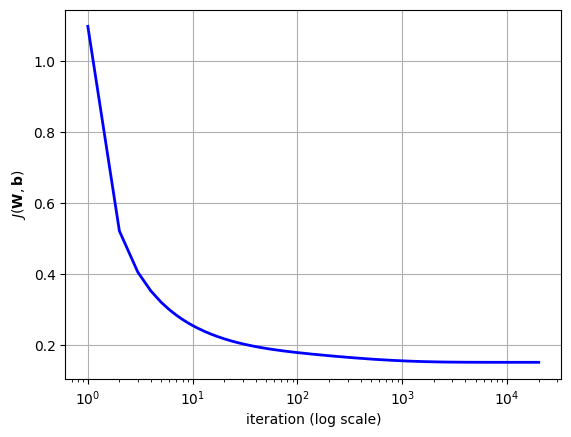

In [6]:
def gradient_descent(X, y, K, alpha=1.0, n_iters=20000):
    """Batch gradient descent for softmax regression from W = 0, b = 0."""
    W, b = np.zeros((K, X.shape[1])), np.zeros(K)
    J_history = np.zeros(n_iters)
    for t in range(n_iters):
        J_history[t] = compute_cost(X, y, W, b)
        dJ_dW, dJ_db = compute_gradient(X, y, W, b)
        W, b = W - alpha * dJ_dW, b - alpha * dJ_db
    return W, b, J_history

W_gd, b_gd, J_hist = gradient_descent(X_train, y_train, K)
y_pred = np.argmax(predict_proba(X_train, W_gd, b_gd), axis=1)
print(f"W =\n{W_gd}\nb = {b_gd}")
print(f"final cost {J_hist[-1]:.4f}, training accuracy {np.mean(y_pred == y_train):.3f}")

plt.semilogx(np.arange(1, len(J_hist) + 1), J_hist, 'b-', lw=2)
plt.xlabel('iteration (log scale)')
plt.ylabel('$J(\\mathbf{W}, \\mathbf{b})$')
plt.grid(True)
plt.show()

## Comparison with scikit-learn

For more than two classes, `LogisticRegression` uses the softmax model by default (older code passes `multi_class='multinomial'`, an argument that has been removed in recent versions). As in Lab 8, a very large $C$ switches the default regularisation off.

In [7]:
sk_model = LogisticRegression(C=1e10, max_iter=10000).fit(X_train, y_train)
print(f"coef_ (shape {sk_model.coef_.shape}):\n{sk_model.coef_}")
print(f"intercept_ (shape {sk_model.intercept_.shape}): {sk_model.intercept_}")
print(f"largest difference in W: {np.max(np.abs(sk_model.coef_ - W_gd)):.4f}")
print(f"largest difference in the probabilities: "
      f"{np.max(np.abs(sk_model.predict_proba(X_train) - predict_proba(X_train, W_gd, b_gd))):.1e}")

coef_ (shape (3, 2)):
[[-4.607  1.633]
 [ 7.266 -6.511]
 [-2.659  4.878]]
intercept_ (shape (3,)): [-0.333  1.307 -0.974]
largest difference in W: 0.0064
largest difference in the probabilities: 4.7e-04


Both methods give the same model. `predict_proba` returns an array of shape $(m, K)$: one row per example, one column per class, each row summing to one; `predict` returns the class with the largest probability.

::: {.callout-note title="The softmax parameters are not unique"}
Adding the same vector $\mathbf c$ to every $\mathbf w_k$ (and the same number to every $b_k$) adds the same amount to every score $z_k$, and the softmax probabilities do not change. Gradient descent started at zero keeps $\sum_k\mathbf w_k = \mathbf 0$, because the rows of $\mathbf P - \mathbf Y$ sum to zero, and scikit-learn picks the same representative, so here even the parameters agree. In general, compare **probabilities**, not parameters. With scikit-learn's default regularisation ($C = 1$) the weights are smaller, and the probabilities differ as well.
:::

## Decision regions

The boundary between classes $j$ and $k$ lies where their scores are equal, $(\mathbf w_j - \mathbf w_k)\cdot\mathbf x + b_j - b_k = 0$: a straight line, or a hyperplane with more features. Each line only matters where $j$ and $k$ are the two most probable classes, so we draw the regions by predicting the class on a grid, rather than drawing the lines.

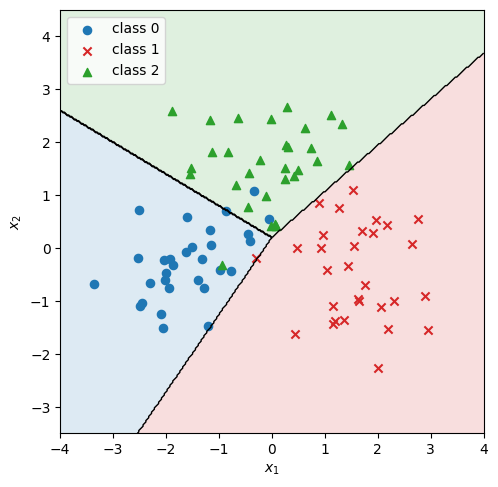

In [8]:
g1, g2 = np.meshgrid(np.linspace(-4, 4, 300), np.linspace(-3.5, 4.5, 300))
grid = np.column_stack([g1.ravel(), g2.ravel()])
regions = np.argmax(predict_proba(grid, W_gd, b_gd), axis=1).reshape(g1.shape)

plt.figure(figsize=(5.5, 5.5))
plt.contourf(g1, g2, regions, levels=[-0.5, 0.5, 1.5, 2.5], colors=colours, alpha=0.15)
plt.contour(g1, g2, regions, levels=[0.5, 1.5], colors='k', linewidths=1)
plot_data(X_train, y_train)
plt.legend(loc='upper left')
plt.show()

## Challenges

1. Show that adding the same vector $\mathbf c$ to every $\mathbf w_k$ does not change the softmax probabilities. Check it numerically with `predict_proba`.
2. Train with scikit-learn's default settings, `LogisticRegression()`. How do the weights and the probabilities change? Does the training accuracy change?
3. Move the class centres closer together (e.g. multiply `centres` by $0.5$). How do the decision regions, the final cost and the accuracy change?
4. Which point of the plane has equal probabilities for all three classes? (*Hint:* solve $z_0 = z_1 = z_2$, a linear system for $x_1, x_2$.)

## Summary

- Softmax regression: one linear score $z_k = \mathbf w_k\cdot\mathbf x + b_k$ per class, and $P(y = k \mid \mathbf x) = e^{z_k}/\sum_j e^{z_j}$; predict the class with the largest probability.
- For $K = 2$ it reduces to binary logistic regression with $\mathbf w = \mathbf w_1 - \mathbf w_0$.
- Cost: cross-entropy $-\frac1m\sum_i\log P(y = y^{(i)} \mid \mathbf x^{(i)})$; gradient $\frac1m(\mathbf P - \mathbf Y)^{\top}\mathbf X$.
- Compute softmax and cross-entropy stably by subtracting the largest score.
- In scikit-learn, `coef_` has shape $(K, n)$ and `predict_proba` shape $(m, K)$.